In [1]:
%pip install duckdb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import duckdb
import pandas as pd
import time
import os

In [3]:
df = pd.read_csv("job_market_india.csv")
print("database shape=",df.shape)

database shape= (835, 6)


In [4]:
df.head()

,Job Title,Location,Salary,Monthly Salary,Locality,State
0,Robotics / STEM Trainer,"Indore, Madhya Pradesh","₹1,80,000 - ₹3,60,000 a year",270000.0,NaN,Madhya Pradesh
1,HTML Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
2,Java Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
3,"Teachers - Pre-Primary and Primary (English, M...","Pulivendla, Andhra Pradesh","₹20,000 - ₹30,000 a month",25000.0,NaN,Andhra Pradesh
4,College Student,Remote,"₹15,000 - ₹20,000 a month",17500.0,Remote,Remote


In [5]:
len(df)

835

In [6]:
df.columns.tolist()

['Job Title', 'Location', 'Salary', 'Monthly Salary', 'Locality', 'State']

In [7]:
df.dtypes

Job Title          object
Location           object
Salary             object
Monthly Salary    float64
Locality           object
State              object
dtype: object

In [10]:
df_100k = df.sample(
    n=100000,
    replace=True,
    random_state=42
)
df_100k.to_csv("job_market_india_100k.csv",index=False)
print("dataset shape=",df_100k.shape)

dataset shape= (100000, 6)


In [11]:
con=duckdb.connect()
con.execute("""
CREATE TABLE jobs AS
SELECT*FROM read_csv_auto('job_market_india_100k.csv')
""")
print(con.execute("SELECT COUNT(*)FROM jobs").fetchone())

(100000,)


In [12]:
query1="""
SELECT 
state,
COUNT(*) AS total_jobs
FROM jobs
GROUP BY state
ORDER BY total_jobs DESC
LIMIT 10;
"""
result1=con.execute(query1).df()
display(result1)

,State,total_jobs
0,Kerala,19384
1,Tamil Nadu,17770
2,Karnataka,12729
3,Remote,10718
4,Maharashtra,9302
5,Delhi,5004
6,Gujarat,4720
7,Uttar Pradesh,3269
8,Telangana,2406
9,West Bengal,2089


In [15]:
query2 = """
SELECT
    State,
    ROUND(AVG("Monthly Salary"), 2) AS avg_monthly_salary
FROM jobs
GROUP BY State
ORDER BY avg_monthly_salary DESC
LIMIT 10;
"""

result2 = con.execute(query2).df()
display(result2)

,State,avg_monthly_salary
0,Chandigarh,240000.00
1,Goa,217073.99
2,India,144824.66
3,Karnataka,140545.42
4,Rajasthan,134544.64
5,Uttar Pradesh,111329.62
6,Maharashtra,101695.12
7,Delhi,98466.38
8,Punjab,85446.13
9,Madhya Pradesh,71227.32


In [21]:
query3 = """
SELECT
    Location,
    COUNT(*) AS total_jobs
FROM jobs
GROUP BY Location
ORDER BY total_jobs DESC
LIMIT 10;
"""

result3 = con.execute(query3).df()
display(result3)

,Location,total_jobs
0,Remote,10718
1,"Bengaluru, Karnataka",7403
2,"Kochi, Kerala",6438
3,"Chennai, Tamil Nadu",2530
4,"Coimbatore, Tamil Nadu",2422
5,"Pune, Maharashtra",2010
6,"Noida, Uttar Pradesh",1975
7,"Delhi, Delhi",1762
8,"Mumbai, Maharashtra",1741
9,"Thiruvananthapuram, Kerala",1576


In [27]:
query4 = """
SELECT
    "Job Title",
    ROUND(AVG("Monthly Salary"), 2) AS avg_monthly_salary
FROM jobs
WHERE "Monthly Salary" IS NOT NULL
GROUP BY "Job Title"
ORDER BY avg_monthly_salary DESC
LIMIT 10;
"""

result4 = con.execute(query4).df()
display(result4)

,Job Title,avg_monthly_salary
0,Cinematography,939847.17
1,Freshers - Delhi,750000.00
2,Team Leader - Operations,675212.83
3,Chartered Accountant/Semi Qualified / ICWA(CMA...,600000.00
4,Cyber Security Trainer,600000.00
5,Fresher Operations Analyst (Construction),575000.00
6,Human Resource,550000.00
7,Google Ads Specialist,550000.00
8,UI/UX Freshers (2024),500000.00
9,Urgent Requirements of CHEMISTRY Teacher for N...,480000.00


In [25]:
df[["Salary","Monthly Salary"]].head(10)

,Salary,Monthly Salary
0,"₹1,80,000 - ₹3,60,000 a year",270000.0
1,Not specified,NaN
2,Not specified,NaN
3,"₹20,000 - ₹30,000 a month",25000.0
4,"₹15,000 - ₹20,000 a month",17500.0
5,Not specified,NaN
6,Not specified,NaN
7,Not specified,NaN
8,"₹14,678 - ₹22,689 a month",18683.5
9,"From ₹12,800 a month",NaN


In [26]:
df[["Salary","Monthly Salary"]].dtypes

Salary             object
Monthly Salary    float64
dtype: object

In [28]:
query5 = """
SELECT
    Locality,
    COUNT(*) AS total_jobs
FROM jobs
GROUP BY Locality
ORDER BY total_jobs DESC
LIMIT 10;
"""

result5 = con.execute(query5).df()
display(result5)

,Locality,total_jobs
0,None,69531
1,Remote,10718
2,Banaswadi,1214
3,India,1057
4,Delhi,1026
5,Borivali East,481
6,Saravanampatti,477
7,Kerala,446
8,Ambli,366
9,Rajarajeshwari Nagar,276


In [29]:
duckdb_queries=[query1,query2,query3,query4,query5]
duckdb_times = []
for i, query in enumerate(duckdb_queries,1):
    start = time.perf_counter()
    for _ in range(5):
        con.execute(query).fetchall()
    end=time.perf_counter()
    avg_time= (end-start)/5
    duckdb_times.append(avg_time)
    print(f"query{i}: {avg_time:.6f} seconds")

query1: 0.011280 seconds
query2: 0.010606 seconds
query3: 0.011071 seconds
query4: 0.010786 seconds
query5: 0.008414 seconds


In [30]:
pandas_queries=[
    lambda: df_100k.groupby("State").size().sort_values(ascending=False).head(10),
    lambda: df_100k.groupby("State")["Monthly Salary"].mean().sort_values(ascending=False).head(10),
    lambda: df_100k.groupby("Location").size().sort_values(ascending=False).head(10),
    lambda: df_100k.dropna(subset=["Monthly Salary"]).groupby("Job Title")["Monthly Salary"].mean().sort_values(ascending=False).head(10),
    lambda: df_100k.groupby("Locality").size().sort_values(ascending=False).head(10)
]
pandas_time = []
for i, query in enumerate(pandas_queries,1):
    start = time.perf_counter()
    for _ in range(5):
        query()
    end = time.perf_counter()
    avg_time= (start - end)/5
    pandas_time.append(avg_time)
    print(f"query{i}:{avg_time:.6f} seconds")

query1:-0.007294 seconds
query2:-0.008257 seconds
query3:-0.007640 seconds
query4:-0.008188 seconds
query5:-0.003533 seconds


In [39]:
comparison = pd.DataFrame({
    "Query":[f"Query{i}" for i in range(1,6)],
    "DuckDB time(seconds)":duckdb_times,
    "Pandas Time(seconds)":pandas_time
})
display(comparison)

,Query,DuckDB time(seconds),Pandas Time(seconds)
0,Query1,0.011280,-0.004754
1,Query2,0.010606,-0.004474
2,Query3,0.011071,-0.005261
3,Query4,0.010786,-0.006920
4,Query5,0.008414,-0.003309


In [43]:
import matplotlib.pyplot as plt

comparison.plot(
    x="Query",
    y=["DuckDB Time (seconds)", "Pandas Time (seconds)"],
    kind="bar",
    figsize=(10, 5),
    title="DuckDB vs Pandas Performance Comparison"
)

plt.ylabel("Execution Time (seconds)")
plt.show()

KeyError: "None of [Index(['DuckDB Time (seconds)', 'Pandas Time (seconds)'], dtype='object')] are in the [columns]"

In [36]:
print(comparison.columns.tolist())
print(comparison)

['Query', 'DuckDB time(seconds)', 'Pandas Time(seconds)']
    Query  DuckDB time(seconds)  Pandas Time(seconds)
0  Query1              0.011280             -0.007294
1  Query2              0.010606             -0.008257
2  Query3              0.011071             -0.007640
3  Query4              0.010786             -0.008188
4  Query5              0.008414             -0.003533


In [40]:
pandas_times = []

for i, query in enumerate(pandas_queries, 1):
    start_time = time.perf_counter()

    for _ in range(5):
        query()

    end_time = time.perf_counter()

    avg_time = (end_time - start_time) / 5
    pandas_times.append(avg_time)

    print(f"Query {i}: {avg_time:.6f} seconds")

Query 1: 0.004299 seconds
Query 2: 0.003933 seconds
Query 3: 0.005165 seconds
Query 4: 0.006715 seconds
Query 5: 0.003549 seconds


In [42]:
comparison = pd.DataFrame({
    "Query": [f"Query{i}" for i in range(1, 6)],
    "DuckDB Time(seconds)": duckdb_times,
    "Pandas Time(seconds)": pandas_times
})

display(comparison)

,Query,DuckDB Time(seconds),Pandas Time(seconds)
0,Query1,0.011280,0.004299
1,Query2,0.010606,0.003933
2,Query3,0.011071,0.005165
3,Query4,0.010786,0.006715
4,Query5,0.008414,0.003549


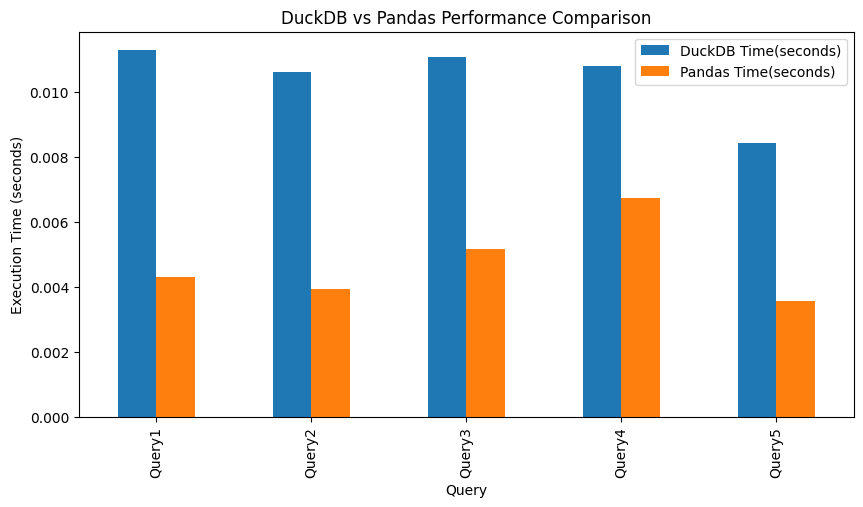

In [45]:
comparison.plot(
    x="Query",
    y=["DuckDB Time(seconds)", "Pandas Time(seconds)"],
    kind="bar",
    figsize=(10, 5),
    title="DuckDB vs Pandas Performance Comparison"
)

plt.ylabel("Execution Time (seconds)")
plt.show()

In [48]:
%pip install polars


   ---------------------------------------- 0.0/911.5 kB ? eta -:--:--
   ---------------------------------------- 0.0/911.5 kB ? eta -:--:--
   ---------------------------------------- 0.0/911.5 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/911.5 kB ? eta -:--:--
   ----------------------- ---------------- 524.3/911.5 kB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 911.5/911.5 kB 1.9 MB/s  0:00:00
   ---------------------------------------- 0.0/53.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/53.9 MB ? eta -:--:--
    --------------------------------------- 1.0/53.9 MB 2.5 MB/s eta 0:00:22
    --------------------------------------- 1.3/53.9 MB 2.5 MB/s eta 0:00:22
   - -------------------------------------- 1.8/53.9 MB 2.5 MB/s eta 0:00:21
   - -------------------------------------- 2.4/53.9 MB 2.4 MB/s eta 0:00:22
   -- ------------------------------------- 2.9/53.9 MB 2.3 MB/s eta 0:00:22
   -- --------------------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
import polars as pl
pl.__version__

'2.1.0'

In [51]:
pl_df= pl.read_csv("job_market_india_100k.csv")
pl_df.shape

(100000, 6)

In [52]:
pl_df.head()

Job Title,Location,Salary,Monthly Salary,Locality,State
str,str,str,f64,str,str
"""Content Creator Intern""","""Remote""","""₹5,000 - ₹10,000 a month""",7500.0,"""Remote""","""Remote"""
"""RO/SRO/ABM – Business Operatio…","""India""","""Not specified""",null,"""India""","""India"""
"""Education Consultant""","""Kasaragod, Kerala""","""₹12,000 - ₹25,000 a month""",18500.0,null,"""Kerala"""
"""Freshers - Delhi""","""Delhi, Delhi""","""₹7,50,000 a year""",750000.0,null,"""Delhi"""
"""HR Co-ordinator""","""Thrissur, Kerala""","""₹12,000 - ₹15,000 a month""",13500.0,null,"""Kerala"""


In [56]:
polars_q1=(
    pl_df.group_by("State").agg(pl.len().alias("total_jobs")).sort("total_jobs",descending=True).head(10)
)
display(polars_q1)

State,total_jobs
str,u32
"""Kerala""",19384
"""Tamil Nadu""",17770
"""Karnataka""",12729
"""Remote""",10718
"""Maharashtra""",9302
"""Delhi""",5004
"""Gujarat""",4720
"""Uttar Pradesh""",3269
"""Telangana""",2406


In [57]:
polars_q2= (
    pl_df.group_by("State").agg(pl.col("Monthly Salary").mean().round(2).alias("avg_monthly_salary")).sort("avg_monthly_salary",
                                                                                                           descending=True).head(10)
)
display(polars_q2)

State,avg_monthly_salary
str,f64
"""Arunachal Pradesh""",null
"""Jammu and Kashmir""",null
"""Chandigarh""",240000.0
"""Goa""",217073.99
"""India""",144824.66
"""Karnataka""",140545.42
"""Rajasthan""",134544.64
"""Uttar Pradesh""",111329.62
"""Maharashtra""",101695.12


In [58]:
polars_q3 = (
    pl_df.group_by("Location").agg(pl.len().alias("total_jobs")).sort("total_jobs",descending=True).head(10)
)
display(polars_q3)

Location,total_jobs
str,u32
"""Remote""",10718
"""Bengaluru, Karnataka""",7403
"""Kochi, Kerala""",6438
"""Chennai, Tamil Nadu""",2530
"""Coimbatore, Tamil Nadu""",2422
"""Pune, Maharashtra""",2010
"""Noida, Uttar Pradesh""",1975
"""Delhi, Delhi""",1762
"""Mumbai, Maharashtra""",1741


In [59]:
polars_q4 = (
    pl_df.filter(pl.col("Monthly Salary").is_not_null()).group_by("Job Title").
    agg(pl.col("Monthly Salary").mean().round(2).alias("avg_monthly_salary")).sort("avg_monthly_salary", descending=True).head(10)
)
display(polars_q4)

Job Title,avg_monthly_salary
str,f64
"""Cinematography""",939847.18
"""Freshers - Delhi""",750000.0
"""Team Leader - Operations""",675212.82
"""Chartered Accountant/Semi Qual…",600000.0
"""Cyber Security Trainer""",600000.0
"""Fresher Operations Analyst (Co…",575000.0
"""Human Resource""",550000.0
"""Google Ads Specialist""",550000.0
"""UI/UX Freshers (2024)""",500000.0


In [60]:
polars_q5 = (
    pl_df.group_by("Locality").agg(pl.len().alias("total_jobs")).sort("total_jobs",descending=True).head(10)
)
print(polars_q5)

shape: (10, 2)
┌──────────────────────┬────────────┐
│ Locality             ┆ total_jobs │
│ ---                  ┆ ---        │
│ str                  ┆ u32        │
╞══════════════════════╪════════════╡
│ null                 ┆ 69531      │
│ Remote               ┆ 10718      │
│ Banaswadi            ┆ 1214       │
│ India                ┆ 1057       │
│ Delhi                ┆ 1026       │
│ Borivali East        ┆ 481        │
│ Saravanampatti       ┆ 477        │
│ Kerala               ┆ 446        │
│ Ambli                ┆ 366        │
│ Rajarajeshwari Nagar ┆ 276        │
└──────────────────────┴────────────┘


In [63]:
polars_queries = [
    lambda: pl_df.group_by("State").agg(pl.len()).sort("len",descending=True).head(10),
    lambda: pl_df.group_by("State").agg(pl.col("Monthly Salary").mean()).sort("Monthly Salary",descending=True).head(10),
    lambda: pl_df.group_by("Location").agg(pl.len()).sort("len",descending=True).head(10),
    lambda: pl_df.filter(pl.col("Monthly Salary").is_not_null()).group_by("Job Title").agg(pl.col("Monthly Salary").mean()).
            sort("Monthly Salary",descending=True).head(10),
    lambda: pl_df.group_by("Locality").agg(pl.len()).sort("len",descending=True).head(10)
]
polars_times = []
for i,queries in enumerate(polars_queries,1):
    start = time.perf_counter()
    for _ in range(5):
        query()
    end = time.perf_counter()
    avg_time=(end-start)/5
    polars_times.append(avg_time)
    print(f"Queries{i}: {avg_time:.6f} seconds")

Queries1: 0.003992 seconds
Queries2: 0.003612 seconds
Queries3: 0.004307 seconds
Queries4: 0.003686 seconds
Queries5: 0.003358 seconds


In [65]:
final_comparison = pd.DataFrame({
    "Query": [f"Query{i}" for i in range(1, 6)],
    "Pandas (seconds)": pandas_times,
    "DuckDB (seconds)": duckdb_times,
    "Polars (seconds)": polars_times
})

display(final_comparison)

,Query,Pandas (seconds),DuckDB (seconds),Polars (seconds)
0,Query1,0.004299,0.011280,0.003992
1,Query2,0.003933,0.010606,0.003612
2,Query3,0.005165,0.011071,0.004307
3,Query4,0.006715,0.010786,0.003686
4,Query5,0.003549,0.008414,0.003358


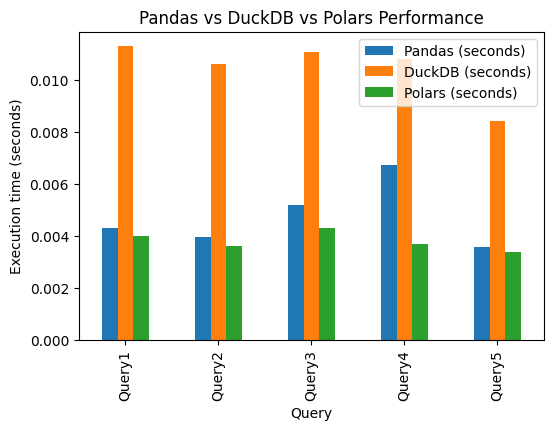

In [66]:
final_comparison.plot(
    x="Query",
    y=["Pandas (seconds)","DuckDB (seconds)","Polars (seconds)"],
    kind="bar",
    figsize=(6,4),
    title="Pandas vs DuckDB vs Polars Performance"
)
plt.ylabel("Execution time (seconds)")
plt.show()